# 1. Importar librerías

In [1]:
import random
import pandas as pd
import matplotlib.pyplot as plt

# 2. Crear tablero

Generamos un tablero de prueba reproducible. Las posiciones reales de las minas se utilizan únicamente para construir las pistas; el algoritmo recibe las pistas y las casillas desconocidas.

In [2]:
random.seed(42)

FILAS = 6
COLUMNAS = 6
TOTAL_MINAS = 8
CASILLAS_REVELADAS = 16

todas = [
    (f, c)
    for f in range(FILAS)
    for c in range(COLUMNAS)
]

# Distribución secreta para generar las pistas
minas_reales = set(random.sample(todas, TOTAL_MINAS))


def vecinos(f, c):
    return [
        (nf, nc)
        for nf in range(max(0, f - 1), min(FILAS, f + 2))
        for nc in range(max(0, c - 1), min(COLUMNAS, c + 2))
        if (nf, nc) != (f, c)
    ]


def contar_minas_reales(f, c):
    return sum(
        pos in minas_reales
        for pos in vecinos(f, c)
    )


# Seleccionar casillas seguras para revelar
seguras = [
    pos for pos in todas
    if pos not in minas_reales
]

reveladas = set(
    random.sample(seguras, CASILLAS_REVELADAS)
)

# None significa casilla desconocida
tablero = [
    [None for _ in range(COLUMNAS)]
    for _ in range(FILAS)
]

for f, c in reveladas:
    tablero[f][c] = contar_minas_reales(f, c)

# Genes: un gen por cada casilla desconocida
desconocidas = [
    (f, c)
    for f in range(FILAS)
    for c in range(COLUMNAS)
    if tablero[f][c] is None
]

MINAS_RESTANTES = TOTAL_MINAS

print("Tablero de pistas:")
for fila in tablero:
    print(fila)

print("\nCantidad de casillas desconocidas:", len(desconocidas))
print("Minas que debe ubicar el algoritmo:", MINAS_RESTANTES)
print("Longitud del cromosoma:", len(desconocidas))

Tablero de pistas:
[2, None, 3, None, None, 1]
[2, None, None, None, 4, 2]
[1, None, None, None, None, None]
[0, None, 2, None, None, None]
[0, 0, 0, None, 1, 1]
[None, 0, 0, None, None, None]

Cantidad de casillas desconocidas: 20
Minas que debe ubicar el algoritmo: 8
Longitud del cromosoma: 20


Comprobar las pistas

In [3]:
errores_pistas = []

for f in range(FILAS):
    for c in range(COLUMNAS):
        pista = tablero[f][c]

        if pista is not None:
            cantidad_real = sum(
                (nf, nc) in minas_reales
                for nf, nc in vecinos(f, c)
            )

            if pista != cantidad_real:
                errores_pistas.append(
                    (f, c, pista, cantidad_real)
                )

print("Cantidad de errores:", len(errores_pistas))
print("Detalles (fila, columna, pista, valor real):")
print(errores_pistas)

Cantidad de errores: 0
Detalles (fila, columna, pista, valor real):
[]


# 3. Definir función de decodificación

Cada cromosoma contiene 20 genes en este ejemplo. Un 1 indica una mina y un 0 indica que no hay mina en esa casilla desconocida.

In [4]:
def decodificar(cromosoma):
    solucion = [fila.copy() for fila in tablero]

    for gen, (f, c) in zip(cromosoma, desconocidas):
        solucion[f][c] = "M" if gen == 1 else "L"

    return solucion

# 4. Calcular penalización y aptitud

La penalización mide los errores en las pistas y la diferencia respecto del total de minas. Una penalización de cero significa que se satisfacen todas las restricciones codificadas.

In [5]:

def calcular_penalizacion(cromosoma):
    error = 0

    # Diccionario con las minas propuestas por el cromosoma
    minas_propuestas = {
        posicion
        for gen, posicion in zip(cromosoma, desconocidas)
        if gen == 1
    }

    # Comprobar las pistas reveladas
    for f in range(FILAS):
        for c in range(COLUMNAS):
            pista = tablero[f][c]

            if pista is not None:
                minas_vecinas = sum(
                    (nf, nc) in minas_propuestas
                    for nf, nc in vecinos(f, c)
                )

                error += abs(pista - minas_vecinas)

    # Comprobar el total de minas
    error += abs(sum(cromosoma) - MINAS_RESTANTES)

    return error



def aptitud(cromosoma):
    return 1 / (1 + calcular_penalizacion(cromosoma))


def solucion_valida(cromosoma):
    return calcular_penalizacion(cromosoma) == 0

Comprobar si la distribución real de minas satisface las restricciones definidas

In [6]:
# Comprobar cada pista individualmente usando el cromosoma real

cromosoma_real = [
    int((f, c) in minas_reales)
    for f, c in desconocidas
]

tablero_prueba = decodificar(cromosoma_real)

errores_decodificacion = []

for f in range(FILAS):
    for c in range(COLUMNAS):
        pista = tablero[f][c]

        if pista is not None:
            cantidad = sum(
                tablero_prueba[nf][nc] == "M"
                for nf, nc in vecinos(f, c)
            )

            if cantidad != pista:
                errores_decodificacion.append(
                    (f, c, pista, cantidad)
                )

print("Errores al decodificar:", errores_decodificacion)
print("Minas en el cromosoma:", sum(cromosoma_real))
print("Minas restantes esperadas:", MINAS_RESTANTES)
print("Penalización total:", calcular_penalizacion(cromosoma_real))

Errores al decodificar: []
Minas en el cromosoma: 8
Minas restantes esperadas: 8
Penalización total: 0


Comprobar que el problema tiene solución

In [7]:
from itertools import combinations

def comprobar_si_existe_solucion():
    n = len(desconocidas)
    cantidad_combinaciones = 0

    # Probar todas las formas de colocar exactamente 8 minas
    for posiciones_minas in combinations(
        range(n), MINAS_RESTANTES
    ):
        cromosoma = [0] * n

        for i in posiciones_minas:
            cromosoma[i] = 1

        cantidad_combinaciones += 1

        if calcular_penalizacion(cromosoma) == 0:
            print("Existe al menos una solución válida.")
            print("Cromosoma válido:", cromosoma)
            print("Penalización:", calcular_penalizacion(cromosoma))
            print("Combinaciones probadas:", cantidad_combinaciones)
            return cromosoma

    print("No se encontró una solución válida.")
    print("Combinaciones probadas:", cantidad_combinaciones)
    return None


solucion_referencia = comprobar_si_existe_solucion()

Existe al menos una solución válida.
Cromosoma válido: [1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
Penalización: 0
Combinaciones probadas: 1109


In [8]:
# Contar todas las distribuciones válidas del tablero chico
n = len(desconocidas)
soluciones_validas = []

for posiciones_minas in combinations(range(n), MINAS_RESTANTES):
    cromosoma = [0] * n

    for i in posiciones_minas:
        cromosoma[i] = 1

    if calcular_penalizacion(cromosoma) == 0:
        soluciones_validas.append(tuple(posiciones_minas))

print("Soluciones válidas encontradas:", len(soluciones_validas))
print("La distribución real es una de ellas:",
      tuple(i for i, g in enumerate(cromosoma_real) if g) in soluciones_validas)

siempre_mina = [
    desconocidas[i] for i in range(n)
    if all(i in s for s in soluciones_validas)
]
nunca_mina = [
    desconocidas[i] for i in range(n)
    if all(i not in s for s in soluciones_validas)
]

print("Casillas que son mina en todas las soluciones:", siempre_mina)
print("Casillas que nunca son mina:", nunca_mina)

Soluciones válidas encontradas: 16
La distribución real es una de ellas: True
Casillas que son mina en todas las soluciones: [(0, 1), (0, 4), (1, 1), (2, 2), (2, 3)]
Casillas que nunca son mina: [(1, 2), (2, 1), (3, 1), (3, 3), (4, 3), (5, 0), (5, 3)]


# 5. Crear población inicial

In [9]:
TAM_POBLACION = 100
MAX_GENERACIONES = 500
PROB_CRUCE = 0.8
PROB_MUTACION = 0.03
TAM_TORNEO = 3


def crear_individuo():
    return [
        random.randint(0, 1)
        for _ in range(len(desconocidas))
    ]


def crear_poblacion():
    return [
        crear_individuo()
        for _ in range(TAM_POBLACION)
    ]


poblacion_inicial = crear_poblacion()

print("Cantidad de individuos:", len(poblacion_inicial))
print("Genes por individuo:", len(poblacion_inicial[0]))
print("Ejemplo de cromosoma:", poblacion_inicial[0])
print("Aptitud del ejemplo:", aptitud(poblacion_inicial[0]))

Cantidad de individuos: 100
Genes por individuo: 20
Ejemplo de cromosoma: [1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0]
Aptitud del ejemplo: 0.038461538461538464


# 6. Selección por torneo

Se eligen tres individuos al azar y se selecciona el de mayor aptitud.

In [10]:
def seleccion_torneo(poblacion, tam_torneo=3):
    candidatos = random.sample(
        poblacion,
        min(tam_torneo, len(poblacion))
    )

    ganador = max(candidatos, key=aptitud)

    return ganador.copy()

# 7. Cruce de un punto

Combina partes de los cromosomas de dos padres para crear nuevos individuos.

In [11]:
def cruce(padre1, padre2, prob_cruce=0.8):
    if len(padre1) < 2 or random.random() >= prob_cruce:
        return padre1.copy(), padre2.copy()

    punto = random.randint(1, len(padre1) - 1)

    hijo1 = padre1[:punto] + padre2[punto:]
    hijo2 = padre2[:punto] + padre1[punto:]

    return hijo1, hijo2

# 8. Mutación

In [12]:
def mutacion(cromosoma, prob_mutacion=0.03):
    hijo = cromosoma.copy()

    for i in range(len(hijo)):
        if random.random() < prob_mutacion:
            hijo[i] = 1 - hijo[i]

    return hijo

# 9. Ejecutar algoritmo genético

In [13]:
def ejecutar_ag(
    semilla=42,
    tam_poblacion=100,
    max_generaciones=500,
    prob_cruce=0.8,
    prob_mutacion=0.03,
    tam_torneo=3
):
    random.seed(semilla)

    poblacion = [
        crear_individuo()
        for _ in range(tam_poblacion)
    ]

    mejor = min(poblacion, key=calcular_penalizacion).copy()
    historial = []

    generaciones_ejecutadas = 0

    for generacion in range(max_generaciones + 1):
        actual = min(poblacion, key=calcular_penalizacion)

        if calcular_penalizacion(actual) < calcular_penalizacion(mejor):
            mejor = actual.copy()

        historial.append({
            "generacion": generacion,
            "mejor_aptitud": aptitud(mejor),
            "mejor_penalizacion": calcular_penalizacion(mejor)
        })

        generaciones_ejecutadas = generacion

        if calcular_penalizacion(mejor) == 0:
            break

        if generacion == max_generaciones:
            break

        # Elitismo: copiar al mejor individuo
        nueva_poblacion = [mejor.copy()]

        while len(nueva_poblacion) < tam_poblacion:
            padre1 = seleccion_torneo(poblacion, tam_torneo)
            padre2 = seleccion_torneo(poblacion, tam_torneo)

            hijo1, hijo2 = cruce(
                padre1, padre2, prob_cruce
            )

            nueva_poblacion.append(
                mutacion(hijo1, prob_mutacion)
            )

            if len(nueva_poblacion) < tam_poblacion:
                nueva_poblacion.append(
                    mutacion(hijo2, prob_mutacion)
                )

        poblacion = nueva_poblacion

    return mejor, generaciones_ejecutadas, historial

# 10. Ejecutar una prueba

In [14]:
mejor, generaciones, historial = ejecutar_ag(
    semilla=42,
    tam_poblacion=TAM_POBLACION,
    max_generaciones=MAX_GENERACIONES,
    prob_cruce=PROB_CRUCE,
    prob_mutacion=PROB_MUTACION,
    tam_torneo=TAM_TORNEO
)

print("Mejor cromosoma:", mejor)
print("Cantidad de minas propuestas:", sum(mejor))
print("Aptitud final:", aptitud(mejor))
print("Penalización final:", calcular_penalizacion(mejor))
print("Generaciones ejecutadas:", generaciones)
print("Solución válida:", solucion_valida(mejor))

Mejor cromosoma: [1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0]
Cantidad de minas propuestas: 8
Aptitud final: 1.0
Penalización final: 0
Generaciones ejecutadas: 9
Solución válida: True


# 11. Mostrar el tablero resuelto

In [15]:
solucion = decodificar(mejor)

minas_propuestas = {
    pos
    for gen, pos in zip(mejor, desconocidas)
    if gen == 1
}

print("Tablero propuesto:")
for f, fila in enumerate(solucion):
    print([
        "M" if (f, c) in minas_propuestas else valor
        for c, valor in enumerate(fila)
    ])

Tablero propuesto:
[2, 'M', 3, 'L', 'M', 1]
[2, 'M', 'L', 'M', 4, 2]
[1, 'L', 'M', 'M', 'L', 'M']
[0, 'L', 2, 'L', 'L', 'L']
[0, 0, 0, 'L', 1, 1]
['L', 0, 0, 'L', 'M', 'L']


# 12. Graficar la evolución de la aptitud

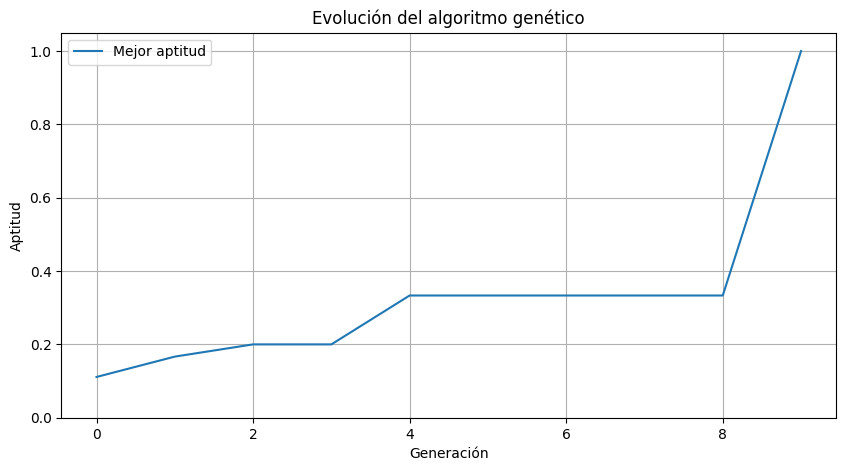

In [16]:
df_historial = pd.DataFrame(historial)

plt.figure(figsize=(10, 5))
plt.plot(
    df_historial["generacion"],
    df_historial["mejor_aptitud"],
    label="Mejor aptitud"
)

plt.xlabel("Generación")
plt.ylabel("Aptitud")
plt.title("Evolución del algoritmo genético")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

# 13. Graficar la penalización

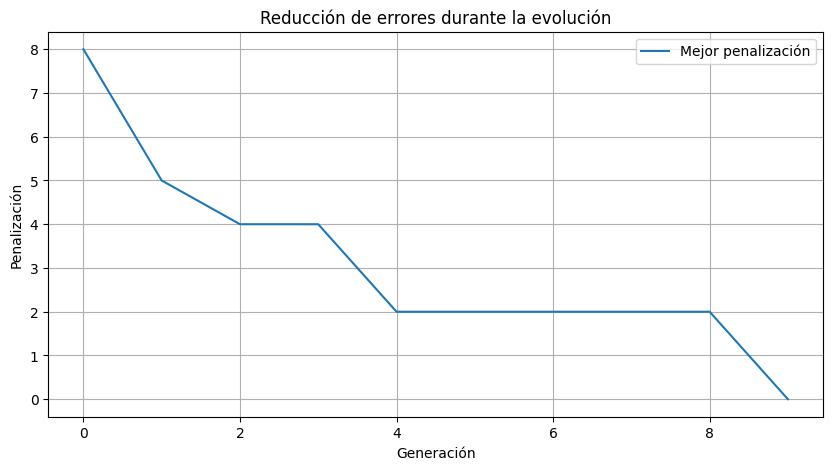

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(
    df_historial["generacion"],
    df_historial["mejor_penalizacion"],
    label="Mejor penalización"
)

plt.xlabel("Generación")
plt.ylabel("Penalización")
plt.title("Reducción de errores durante la evolución")
plt.grid(True)
plt.legend()
plt.show()

# 14. Comparar cinco probabilidades de mutación

In [18]:
probabilidades_mutacion = [0.01, 0.03, 0.05, 0.10, 0.20]

resultados = []
historiales = {}

for i, prob in enumerate(probabilidades_mutacion):
    mejor_i, generaciones_i, historial_i = ejecutar_ag(
        semilla=101 + i,
        tam_poblacion=100,
        max_generaciones=500,
        prob_cruce=0.8,
        prob_mutacion=prob,
        tam_torneo=3
    )

    penalizacion_final = calcular_penalizacion(mejor_i)

    resultados.append({
        "corrida": i + 1,
        "poblacion": 100,
        "cruce": 0.8,
        "mutacion": prob,
        "torneo": 3,
        "mejor_cromosoma": mejor_i,
        "aptitud_final": aptitud(mejor_i),
        "penalizacion_final": penalizacion_final,
        "generaciones_ejecutadas": generaciones_i,
        "solucion_valida": penalizacion_final == 0
    })

    historiales[prob] = historial_i

df_resultados = pd.DataFrame(resultados)

display(df_resultados)

,corrida,poblacion,cruce,mutacion,torneo,mejor_cromosoma,aptitud_final,penalizacion_final,generaciones_ejecutadas,solucion_valida
0,1,100,0.8,0.01,3,"[1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, ...",1.0,0,7,True
1,2,100,0.8,0.03,3,"[1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, ...",1.0,0,8,True
2,3,100,0.8,0.05,3,"[1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, ...",1.0,0,7,True
3,4,100,0.8,0.10,3,"[1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, ...",1.0,0,10,True
4,5,100,0.8,0.20,3,"[1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, ...",1.0,0,8,True


# Graficar la evolución de cada corrida

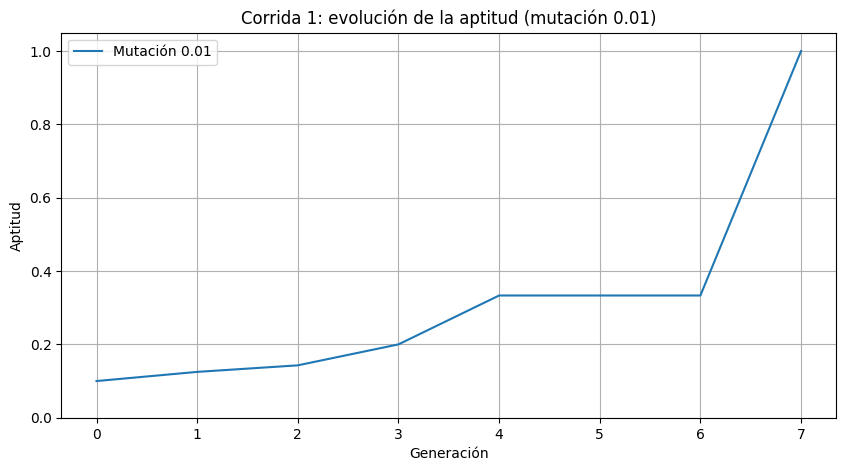

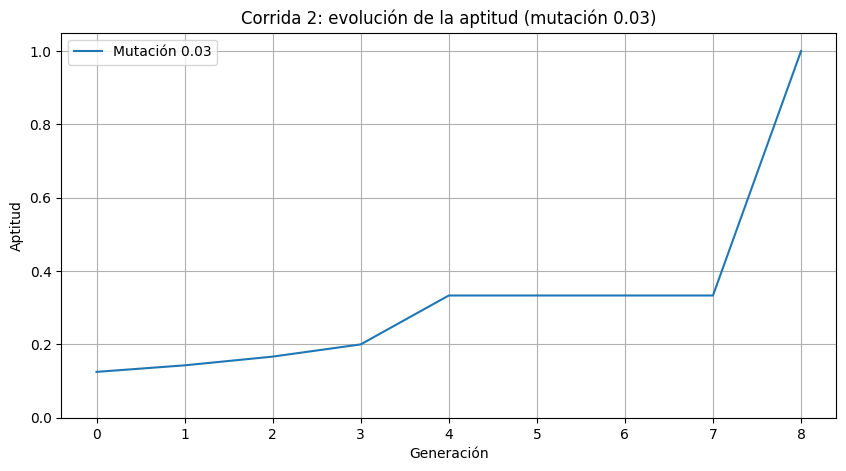

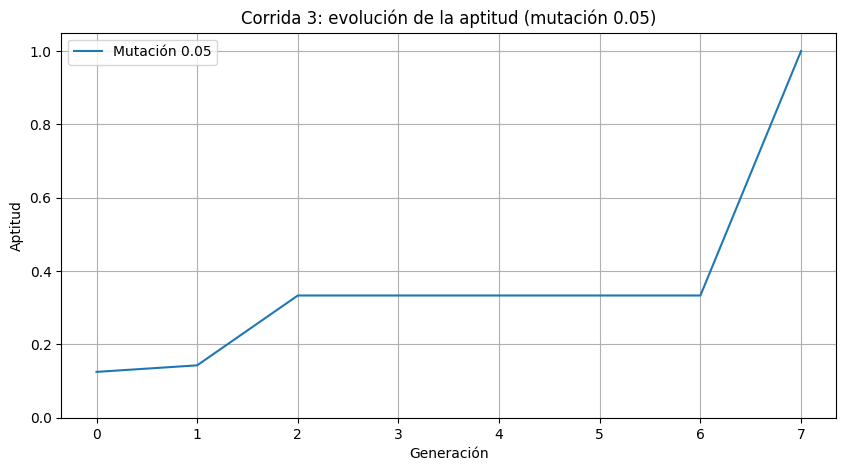

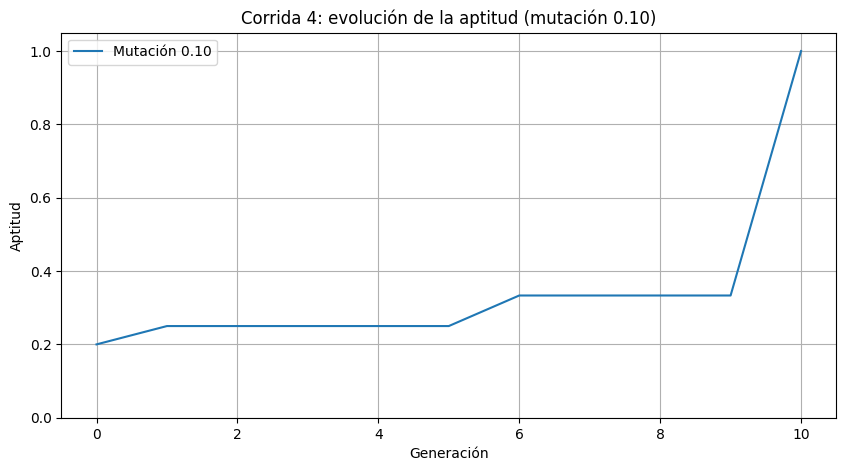

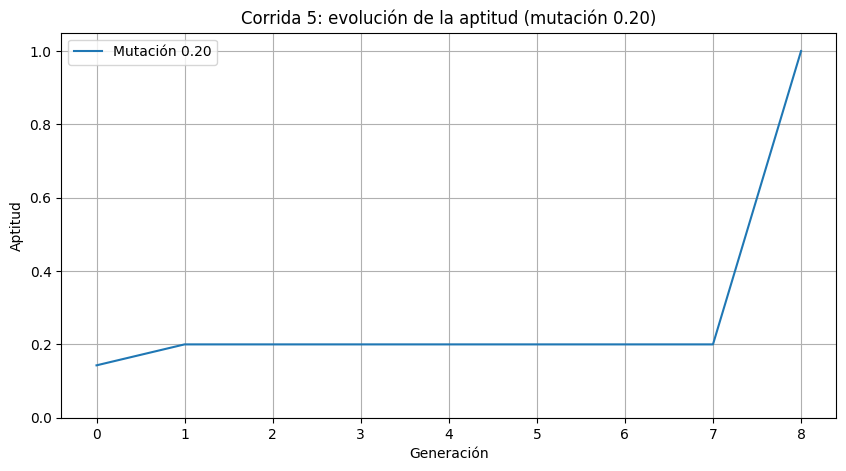

In [19]:
for i, prob in enumerate(probabilidades_mutacion):
    df = pd.DataFrame(historiales[prob])

    plt.figure(figsize=(10, 5))
    plt.plot(
        df["generacion"],
        df["mejor_aptitud"],
        label=f"Mutación {prob:.2f}"
    )

    plt.xlabel("Generación")
    plt.ylabel("Aptitud")
    plt.title(f"Corrida {i + 1}: evolución de la aptitud (mutación {prob:.2f})")
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.legend()
    plt.savefig(f"corrida_{i + 1}_aptitud.png", dpi=150, bbox_inches="tight")
    plt.show()

# Interpretar la mejor solución de cada corrida

In [20]:
for r in resultados:
    cromo = r["mejor_cromosoma"]

    print(f"Corrida {r['corrida']} (mutación {r['mutacion']:.2f})")
    print("Generaciones ejecutadas:", r["generaciones_ejecutadas"])
    print("Penalización final:", r["penalizacion_final"])
    print("Solución válida:", r["solucion_valida"])
    print("Minas propuestas:", sum(cromo))
    print("Coincide con la distribución real:", cromo == cromosoma_real)
    print("Tablero propuesto:")
    for fila in decodificar(cromo):
        print(fila)
    print()

Corrida 1 (mutación 0.01)
Generaciones ejecutadas: 7
Penalización final: 0
Solución válida: True
Minas propuestas: 8
Coincide con la distribución real: False
Tablero propuesto:
[2, 'M', 3, 'M', 'M', 1]
[2, 'M', 'L', 'L', 4, 2]
[1, 'L', 'M', 'M', 'L', 'M']
[0, 'L', 2, 'L', 'L', 'L']
[0, 0, 0, 'L', 1, 1]
['L', 0, 0, 'L', 'M', 'L']

Corrida 2 (mutación 0.03)
Generaciones ejecutadas: 8
Penalización final: 0
Solución válida: True
Minas propuestas: 8
Coincide con la distribución real: False
Tablero propuesto:
[2, 'M', 3, 'L', 'M', 1]
[2, 'M', 'L', 'M', 4, 2]
[1, 'L', 'M', 'M', 'M', 'L']
[0, 'L', 2, 'L', 'M', 'L']
[0, 0, 0, 'L', 1, 1]
['L', 0, 0, 'L', 'L', 'L']

Corrida 3 (mutación 0.05)
Generaciones ejecutadas: 7
Penalización final: 0
Solución válida: True
Minas propuestas: 8
Coincide con la distribución real: False
Tablero propuesto:
[2, 'M', 3, 'M', 'M', 1]
[2, 'M', 'L', 'L', 4, 2]
[1, 'L', 'M', 'M', 'L', 'M']
[0, 'L', 2, 'L', 'L', 'L']
[0, 0, 0, 'L', 1, 1]
['L', 0, 0, 'L', 'L', 'M']

Corr

# Repetir la comparación de mutación con 30 semillas

Con una sola corrida por probabilidad no se puede concluir nada, porque la diferencia de generaciones puede ser azar. Acá se repite cada probabilidad con 30 semillas distintas y se resume.

In [21]:
semillas = range(1000, 1030)  # 30 semillas distintas
resumen = []

for prob in probabilidades_mutacion:
    generaciones_lista = []
    validas = 0

    for semilla in semillas:
        mejor_s, generaciones_s, _ = ejecutar_ag(
            semilla=semilla,
            tam_poblacion=100,
            max_generaciones=500,
            prob_cruce=0.8,
            prob_mutacion=prob,
            tam_torneo=3
        )

        generaciones_lista.append(generaciones_s)
        validas += solucion_valida(mejor_s)

    serie = pd.Series(generaciones_lista)

    resumen.append({
        "mutacion": prob,
        "corridas": len(semillas),
        "soluciones_validas": validas,
        "generaciones_media": round(serie.mean(), 1),
        "generaciones_desvio": round(serie.std(), 1),
        "generaciones_min": serie.min(),
        "generaciones_max": serie.max()
    })

df_resumen_mutacion = pd.DataFrame(resumen)
display(df_resumen_mutacion)

df_resumen_mutacion.to_csv("resumen_mutacion_30_semillas.csv", index=False)

,mutacion,corridas,soluciones_validas,generaciones_media,generaciones_desvio,generaciones_min,generaciones_max
0,0.01,30,30,6.7,3.3,3,19
1,0.03,30,30,6.6,2.4,3,12
2,0.05,30,30,6.5,3.0,3,15
3,0.10,30,30,9.1,4.5,1,21
4,0.20,30,30,30.5,25.5,1,93


# 15. Graficar la comparación de mutaciones

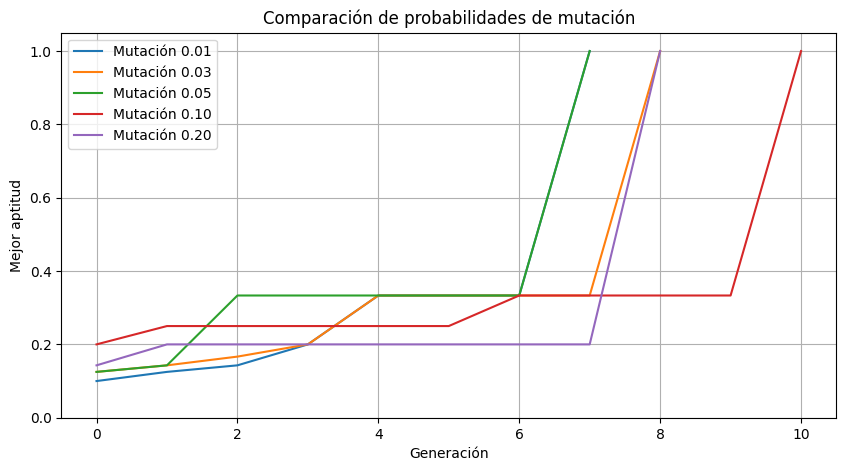

In [22]:
plt.figure(figsize=(10, 5))

for prob, historial_i in historiales.items():
    df = pd.DataFrame(historial_i)

    plt.plot(
        df["generacion"],
        df["mejor_aptitud"],
        label=f"Mutación {prob:.2f}"
    )

plt.xlabel("Generación")
plt.ylabel("Mejor aptitud")
plt.title("Comparación de probabilidades de mutación")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

# 16. Guardar los resultados

In [23]:
# Unir los historiales de las 5 corridas en una sola tabla
filas = []

for i, prob in enumerate(probabilidades_mutacion):
    for registro in historiales[prob]:
        filas.append({
            "corrida": i + 1,
            "mutacion": prob,
            **registro
        })

df_historiales = pd.DataFrame(filas)

# Guardar los archivos
df_resultados.to_csv("resultados_corridas.csv", index=False)
df_historiales.to_csv("historiales_corridas.csv", index=False)
df_historial.to_csv("historial_aptitud.csv", index=False)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.


# 17. Instancia grande (16×16, 40 minas)

El tablero de 6×6 se puede resolver por fuerza bruta. Acá se usa un tablero mucho más grande, donde probar todas las combinaciones no es viable.

In [24]:
import math

FILAS_G = 16
COLUMNAS_G = 16
MINAS_G = 40
FRACCION_REVELADA = 0.6  # fracción de casillas seguras que se muestran como pista

rng = random.Random(7)

todas_g = [(f, c) for f in range(FILAS_G) for c in range(COLUMNAS_G)]
minas_reales_g = set(rng.sample(todas_g, MINAS_G))


def vecinos_g(f, c):
    return [
        (nf, nc)
        for nf in range(max(0, f - 1), min(FILAS_G, f + 2))
        for nc in range(max(0, c - 1), min(COLUMNAS_G, c + 2))
        if (nf, nc) != (f, c)
    ]


seguras_g = [p for p in todas_g if p not in minas_reales_g]
reveladas_g = set(rng.sample(seguras_g, int(len(seguras_g) * FRACCION_REVELADA)))

# Un gen por cada casilla desconocida
desconocidas_g = [p for p in todas_g if p not in reveladas_g]
indice_g = {p: i for i, p in enumerate(desconocidas_g)}

# Cada pista se guarda como (valor, lista de genes vecinos desconocidos)
pistas_g = []
for p in reveladas_g:
    valor = sum(v in minas_reales_g for v in vecinos_g(*p))
    genes_vecinos = [indice_g[v] for v in vecinos_g(*p) if v in indice_g]
    if genes_vecinos:
        pistas_g.append((valor, genes_vecinos))

cromosoma_real_g = [int(p in minas_reales_g) for p in desconocidas_g]

print("Casillas desconocidas (longitud del cromosoma):", len(desconocidas_g))
print("Minas a ubicar:", MINAS_G)
print("Pistas con al menos una casilla vecina desconocida:", len(pistas_g))
print(f"Combinaciones posibles: C({len(desconocidas_g)}, {MINAS_G}) = {math.comb(len(desconocidas_g), MINAS_G):.2e}")

Casillas desconocidas (longitud del cromosoma): 127
Minas a ubicar: 40
Pistas con al menos una casilla vecina desconocida: 128
Combinaciones posibles: C(127, 40) = 1.75e+33


In [25]:
def penalizacion_g(cromosoma):
    error = 0

    for valor, genes in pistas_g:
        error += abs(valor - sum(cromosoma[i] for i in genes))

    error += abs(sum(cromosoma) - MINAS_G)
    return error


def ejecutar_ag_grande(
    semilla,
    tam_poblacion,
    max_generaciones,
    prob_cruce=0.8,
    prob_mutacion=0.01,
    tam_torneo=3
):
    random.seed(semilla)
    n = len(desconocidas_g)

    poblacion = [
        [random.randint(0, 1) for _ in range(n)]
        for _ in range(tam_poblacion)
    ]

    mejor = min(poblacion, key=penalizacion_g).copy()
    historial = []

    for generacion in range(max_generaciones + 1):
        penalizaciones = [penalizacion_g(x) for x in poblacion]
        i_mejor = penalizaciones.index(min(penalizaciones))

        if penalizaciones[i_mejor] < penalizacion_g(mejor):
            mejor = poblacion[i_mejor].copy()

        pen_mejor = penalizacion_g(mejor)
        historial.append({
            "generacion": generacion,
            "mejor_aptitud": 1 / (1 + pen_mejor),
            "mejor_penalizacion": pen_mejor
        })

        if pen_mejor == 0 or generacion == max_generaciones:
            break

        aptitudes = [1 / (1 + p) for p in penalizaciones]

        def torneo():
            candidatos = random.sample(range(tam_poblacion), tam_torneo)
            ganador = max(candidatos, key=lambda i: aptitudes[i])
            return poblacion[ganador].copy()

        # Elitismo: se conserva el mejor individuo
        nueva_poblacion = [mejor.copy()]

        while len(nueva_poblacion) < tam_poblacion:
            hijo1, hijo2 = cruce(torneo(), torneo(), prob_cruce)
            nueva_poblacion.append(mutacion(hijo1, prob_mutacion))

            if len(nueva_poblacion) < tam_poblacion:
                nueva_poblacion.append(mutacion(hijo2, prob_mutacion))

        poblacion = nueva_poblacion

    return mejor, generacion, historial

In [26]:
configuraciones_g = [
    {"poblacion": 100, "mutacion": 0.01},
    {"poblacion": 100, "mutacion": 0.005},
    {"poblacion": 300, "mutacion": 0.005},
    {"poblacion": 300, "mutacion": 0.01},
    {"poblacion": 300, "mutacion": 0.02},
]

resultados_g = []
historiales_g = {}

for i, cfg in enumerate(configuraciones_g):
    mejor_g, generaciones_g, historial_g = ejecutar_ag_grande(
        semilla=201 + i,
        tam_poblacion=cfg["poblacion"],
        max_generaciones=1500,
        prob_cruce=0.8,
        prob_mutacion=cfg["mutacion"],
        tam_torneo=3
    )

    pen_g = penalizacion_g(mejor_g)

    resultados_g.append({
        "corrida": i + 1,
        "poblacion": cfg["poblacion"],
        "cruce": 0.8,
        "mutacion": cfg["mutacion"],
        "torneo": 3,
        "mejor_cromosoma": mejor_g,
        "aptitud_final": 1 / (1 + pen_g),
        "penalizacion_final": pen_g,
        "generaciones_ejecutadas": generaciones_g,
        "solucion_valida": pen_g == 0,
        "coincide_con_real": mejor_g == cromosoma_real_g
    })

    historiales_g[i + 1] = historial_g

df_resultados_g = pd.DataFrame(resultados_g)
display(df_resultados_g.drop(columns="mejor_cromosoma"))

,corrida,poblacion,cruce,mutacion,torneo,aptitud_final,penalizacion_final,generaciones_ejecutadas,solucion_valida,coincide_con_real
0,1,100,0.8,0.010,3,0.500000,1,1500,False,False
1,2,100,0.8,0.005,3,0.250000,3,1500,False,False
2,3,300,0.8,0.005,3,0.166667,5,1500,False,False
3,4,300,0.8,0.010,3,0.500000,1,1500,False,False
4,5,300,0.8,0.020,3,1.000000,0,471,True,False


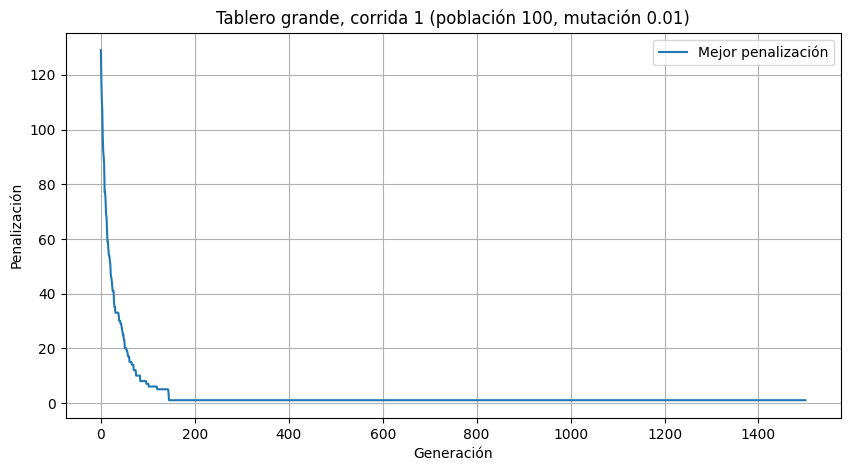

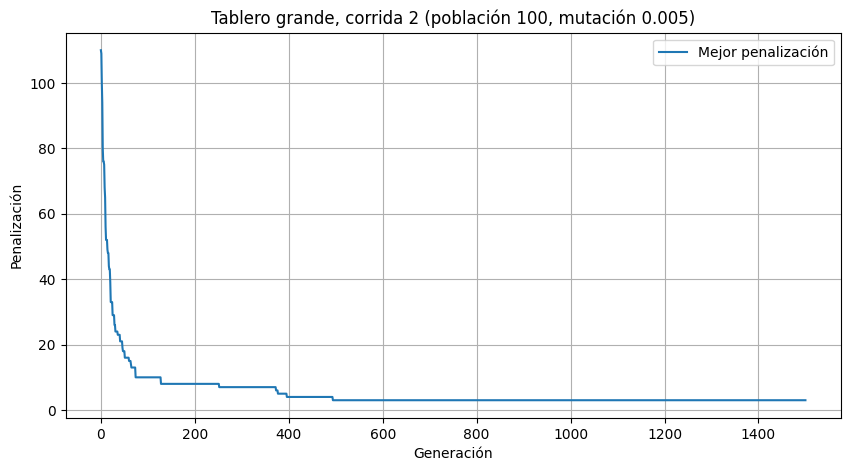

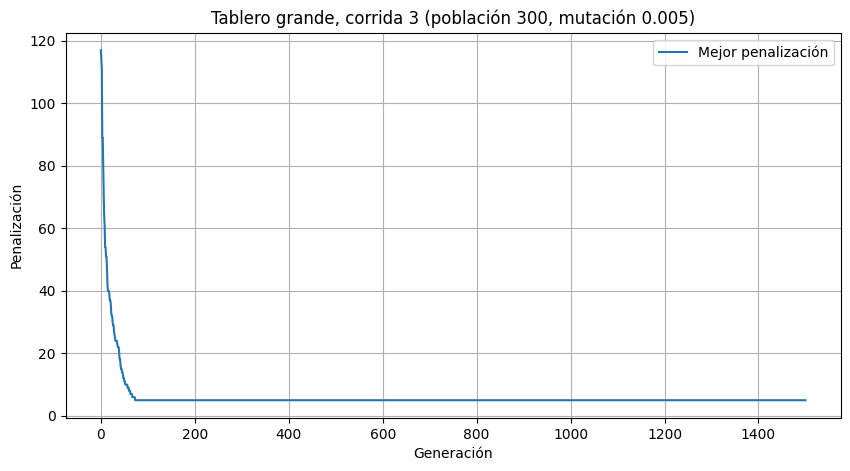

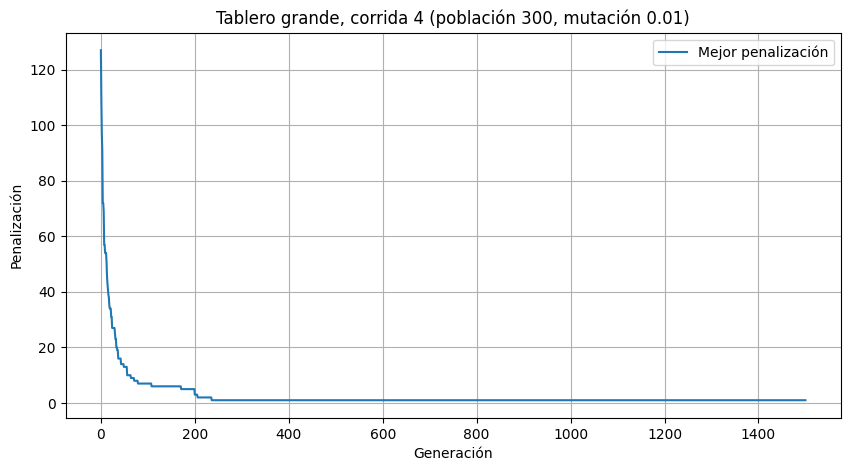

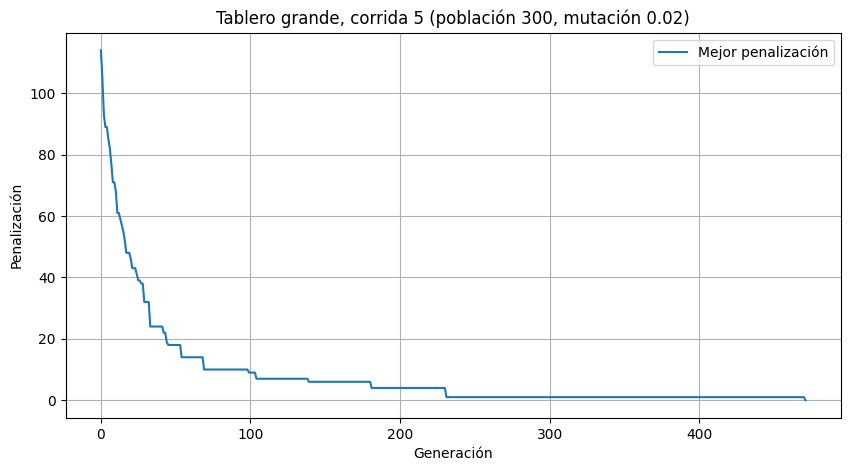

In [27]:
for i, cfg in enumerate(configuraciones_g):
    df = pd.DataFrame(historiales_g[i + 1])

    plt.figure(figsize=(10, 5))
    plt.plot(df["generacion"], df["mejor_penalizacion"], label="Mejor penalización")
    plt.xlabel("Generación")
    plt.ylabel("Penalización")
    plt.title(
        f"Tablero grande, corrida {i + 1} "
        f"(población {cfg['poblacion']}, mutación {cfg['mutacion']})"
    )
    plt.grid(True)
    plt.legend()
    plt.savefig(f"grande_corrida_{i + 1}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [28]:
def mostrar_tablero_g(cromosoma):
    minas = {p for gen, p in zip(cromosoma, desconocidas_g) if gen == 1}

    for f in range(FILAS_G):
        fila = []
        for c in range(COLUMNAS_G):
            if (f, c) in reveladas_g:
                fila.append(str(sum(v in minas_reales_g for v in vecinos_g(f, c))))
            elif (f, c) in minas:
                fila.append("M")
            else:
                fila.append("L")
        print(" ".join(fila))


for r in resultados_g:
    print(f"Corrida {r['corrida']} (población {r['poblacion']}, mutación {r['mutacion']})")
    print("Generaciones:", r["generaciones_ejecutadas"],
          "| Penalización:", r["penalizacion_final"],
          "| Válida:", r["solucion_valida"],
          "| Coincide con la real:", r["coincide_con_real"])
    mostrar_tablero_g(r["mejor_cromosoma"])
    print()

Corrida 1 (población 100, mutación 0.01)
Generaciones: 1500 | Penalización: 1 | Válida: False | Coincide con la real: False
1 2 L M L 1 L L L M L M M 2 M M
L M M L L M L M L 2 2 2 2 2 3 M
1 2 2 1 L 3 L L M 3 1 L L 1 2 1
0 L 0 L L L M 3 M M 1 L 1 M 1 L
0 L 0 0 0 1 L 2 L 2 L L L L 2 0
L L L L L 1 1 L 0 0 1 2 3 M L 1
0 0 L L L M 1 L L 0 1 M M 2 2 M
L 1 L L 1 L L 0 L L L 2 3 2 L L
2 M L 1 2 1 L 0 1 M L 0 1 M 1 0
M L 3 M L M L 1 1 1 1 0 L 1 1 0
M M 2 1 3 M M 1 L 0 0 0 L 0 0 0
2 2 1 0 1 2 2 L 0 L 0 L 0 0 0 L
L 1 2 2 L L 0 L 0 0 0 0 L 0 1 L
0 L M M 1 1 L 2 1 L 0 L L L 1 M
L 2 3 L 2 2 M L M L L 2 L 1 1 L
0 1 M 2 M L 1 2 L 2 M 2 M L L 0

Corrida 2 (población 100, mutación 0.005)
Generaciones: 1500 | Penalización: 3 | Válida: False | Coincide con la real: False
1 2 L M L 1 L M L M L M M 2 M M
L M M L L L M M L 2 2 2 2 2 3 M
1 2 2 1 L 3 L L M 3 1 L L 1 2 1
0 L 0 L L L L 3 M M 1 L 1 M 1 L
0 L 0 0 0 1 M 2 L 2 L L L L 2 0
L L L L L 1 1 L 0 0 1 2 3 M L 1
0 0 L L L L 1 L L 0 1 M M 2 2 M
L 1 L L 1 M L 

In [29]:
filas_g = []
for corrida, historial_g in historiales_g.items():
    for registro in historial_g:
        filas_g.append({"corrida": corrida, **registro})

pd.DataFrame(filas_g).to_csv("historiales_corridas_grande.csv", index=False)
df_resultados_g.to_csv("resultados_corridas_grande.csv", index=False)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.
